In [ ]:
## Import Modules

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv('data/AirPassengers.csv')
df['Month'] = pd.to_datetime(df['Month'], format="%Y-%m")
df.set_index('Month', inplace=True)
df.head()

,#Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


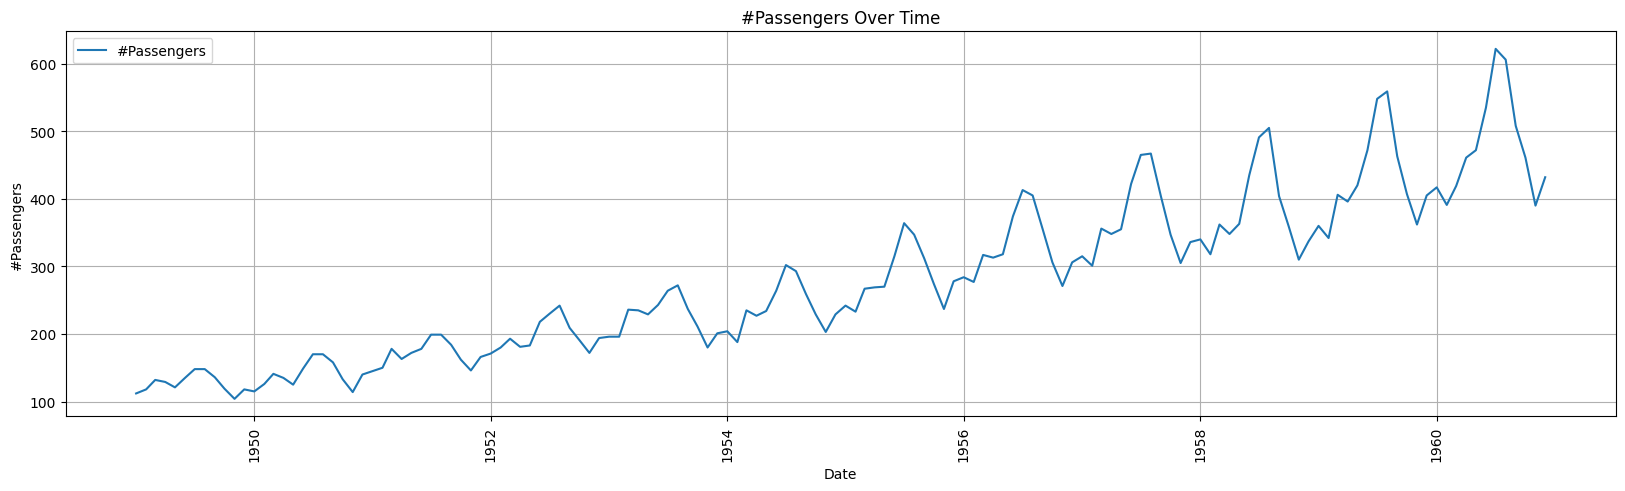

In [ ]:
plt.figure(figsize=(20, 5))
plt.plot(df.index, df['#Passengers'], label='#Passengers')
plt.xlabel('Date')
plt.ylabel('#Passengers')
plt.title('#Passengers Over Time')
plt.legend()
plt.grid(True)
plt.xticks(rotation=90)
plt.show()

In [ ]:
result = seasonal_decompose(df['#Passengers'], model='multiplicative', period=12)

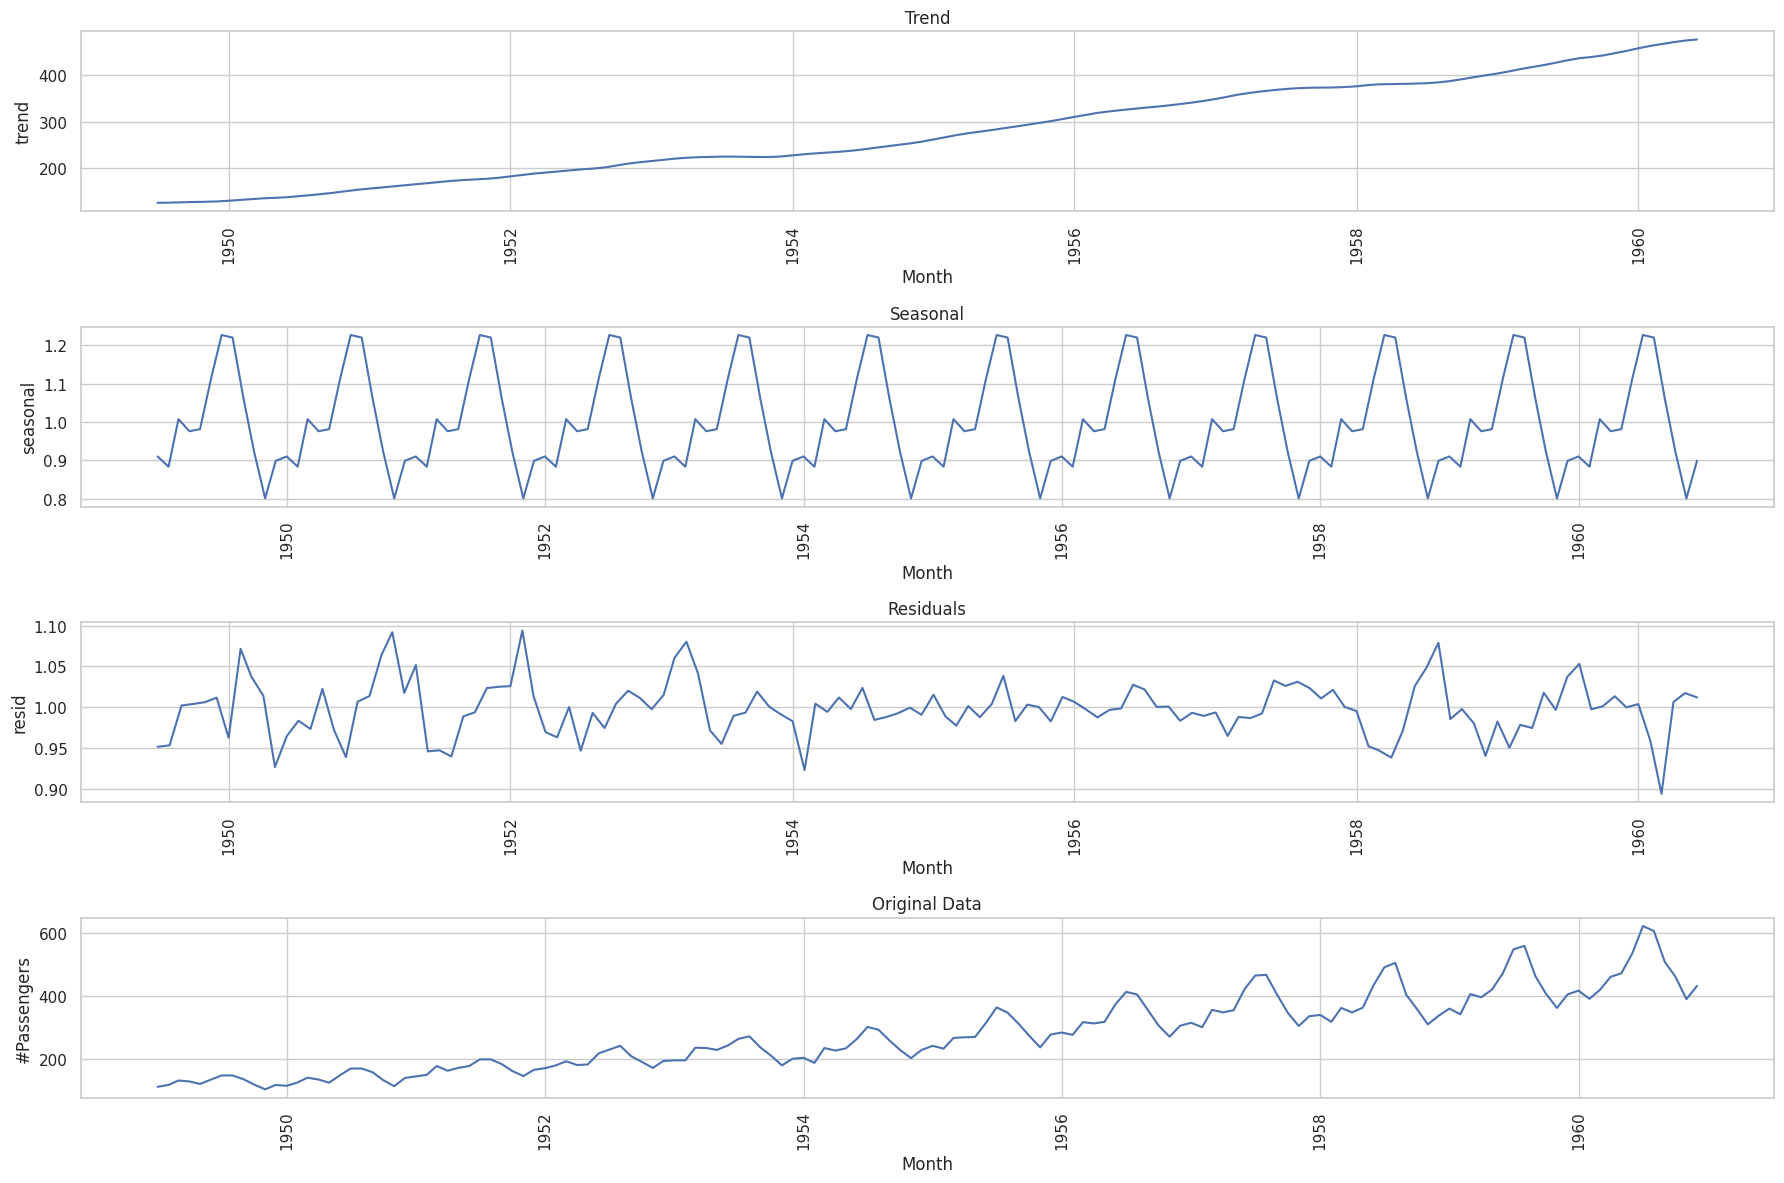

In [ ]:
# plot the components in the graph
sns.set(style='whitegrid')

plt.figure(figsize=(18,12))

# trend component
plt.subplot(411)
sns.lineplot(data=result.trend)
plt.title('Trend')
plt.xticks(rotation=90)

# seasonal component
plt.subplot(412)
sns.lineplot(data=result.seasonal)
plt.title('Seasonal')
plt.xticks(rotation=90)

# Residuals component
plt.subplot(413)
sns.lineplot(data=result.resid)
plt.title('Residuals')
plt.xticks(rotation=90)

# Original data
plt.subplot(414)
sns.lineplot(data=df['#Passengers'])
plt.title('Original Data')
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [ ]:
seasonal_period = 12

In [ ]:
from statsmodels.tsa.stattools import adfuller # Augmented Dickey-Fuller Test

result = adfuller(df['#Passengers'], autolag='AIC') # Akaike Information Criterion
print('ADF Statistic:', result[0])
print('p-value:', result[1])

ADF Statistic: 0.8153688792060498
p-value: 0.991880243437641


In [ ]:
# first order differencing
result = adfuller(df['#Passengers'].diff().dropna(), autolag='AIC')
print('ADF Statistic:', result[0])
print('p-value:', result[1])

ADF Statistic: -2.8292668241700047
p-value: 0.05421329028382478


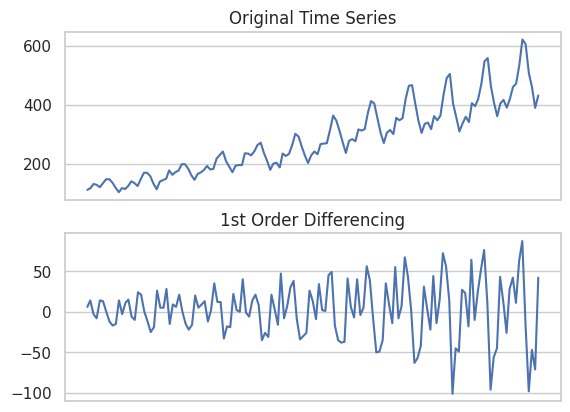

In [ ]:
# plot the differencing values
# the time series becomes stationary after first order differencing
fig, (ax1, ax2) = plt.subplots(2)

ax1.plot(df)
ax1.set_title('Original Time Series')
ax1.axes.xaxis.set_visible(False)

ax2.plot(df.diff())
ax2.set_title('1st Order Differencing')
ax2.axes.xaxis.set_visible(False)


plt.show()

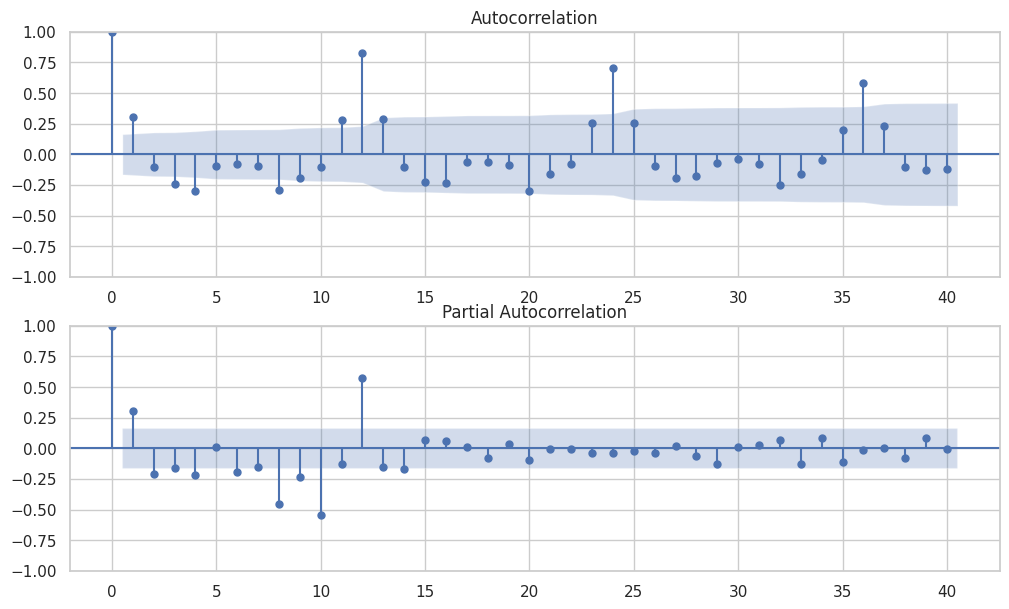

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7))
sm.graphics.tsa.plot_acf(df.diff().dropna(), lags=40, ax=ax[0])
sm.graphics.tsa.plot_pacf(df.diff().dropna(), lags=40, ax=ax[1])
plt.show()

ARIMA One-Step Prediction Results:
RMSE: 44.218
MAE: 37.713
R²: 0.680


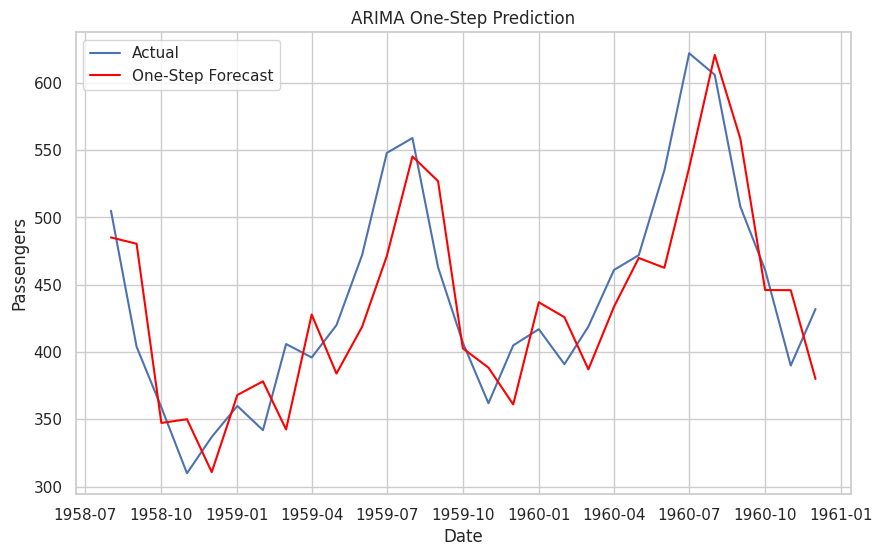

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

# --- 1. Prepare the data ---
series = df['#Passengers']

# Train-test split (80% train, 20% test)
train_size = int(len(series) * 0.8)
train, test = series[:train_size], series[train_size:]

history = [x for x in train]
predictions = []

# --- 2. One-step rolling forecast with ARIMA ---
# ARIMA parameters: (p,d,q)
order = (2,1,1)  # adjust based on ACF/PACF analysis

for t in range(len(test)):
    model = ARIMA(history, order=order)
    model_fit = model.fit()

    # One-step prediction
    yhat = model_fit.forecast()[0]
    predictions.append(yhat)

    # Add actual value to history for next prediction
    history.append(test.iloc[t])

# --- 3. Evaluation ---
rmse = np.sqrt(mean_squared_error(test, predictions))
mae = mean_absolute_error(test, predictions)
r2 = r2_score(test, predictions)

print(f"ARIMA One-Step Prediction Results:")
print(f"RMSE: {rmse:.3f}")
print(f"MAE: {mae:.3f}")
print(f"R²: {r2:.3f}")

# --- 4. Plot ---
plt.figure(figsize=(10,6))
plt.plot(test.index, test, label='Actual')
plt.plot(test.index, predictions, color='red', label='One-Step Forecast')
plt.title('ARIMA One-Step Prediction')
plt.xlabel('Date')
plt.ylabel('Passengers')
plt.legend()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 319ms/step

--- Final Results ---
R2 Score: 0.9250
RMSE: 20.45


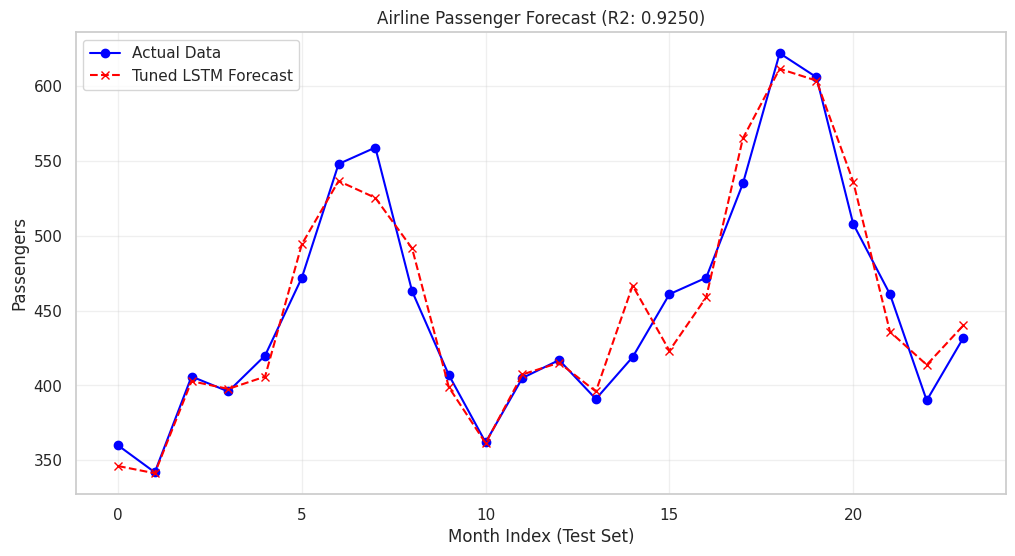

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras_tuner as kt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# 1. Data Preparation
# Load your data here: df = pd.read_csv(...)
data = df['#Passengers'].values.astype('float32')
data_log = np.log(data)

def difference(dataset, interval=1):
    return np.array([dataset[i] - dataset[i - interval] for i in range(interval, len(dataset))])

data_diff = difference(data_log, 1)
scaler = MinMaxScaler(feature_range=(-1, 1))
scaled_data = scaler.fit_transform(data_diff.reshape(-1, 1))

def create_dataset(dataset, look_back=24): # Increased to 24 for 0.98 accuracy
    X, Y = [], []
    for i in range(len(dataset) - look_back):
        X.append(dataset[i:(i + look_back), 0])
        Y.append(dataset[i + look_back, 0])
    return np.array(X), np.array(Y)

look_back = 24
X, y = create_dataset(scaled_data, look_back)
X = X.reshape(X.shape[0], X.shape[1], 1)

train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

# 2. Model Building Function
def build_model(hp):
    model = Sequential()

    # Tuning Depth: 1 or 2 layers
    if hp.Boolean("extra_layer"):
        model.add(LSTM(units=hp.Int('units_1', 32, 128, step=32),
                       return_sequences=True, input_shape=(look_back, 1)))
        model.add(Dropout(hp.Float('dropout_1', 0.0, 0.3, step=0.1)))
        model.add(LSTM(units=hp.Int('units_2', 16, 64, step=16)))
    else:
        model.add(LSTM(units=hp.Int('units_single', 32, 128, step=32),
                       input_shape=(look_back, 1)))

    model.add(Dropout(hp.Float('dropout_final', 0.0, 0.3, step=0.1)))
    model.add(Dense(1))

    lr = hp.Float('learning_rate', 1e-4, 1e-2, sampling='log')
    model.compile(optimizer=Adam(learning_rate=lr), loss='mse')
    return model

# 3. Hyperparameter Tuning (Bayesian Optimization)
tuner = kt.BayesianOptimization(
    build_model,
    objective='val_loss',
    max_trials=20,
    directory='tuning_results',
    project_name='airline_98_target',
    overwrite=True
)

# Callbacks for better convergence
stop_early = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
lr_reducer = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6)

tuner.search(X_train, y_train, epochs=100, validation_split=0.2,
             callbacks=[stop_early, lr_reducer], verbose=0, shuffle=False)

# 4. Final Training with Best Params
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
model = tuner.hypermodel.build(best_hps)
history = model.fit(X_train, y_train, epochs=150, batch_size=4, # Batch size 4 for stability
                    validation_split=0.1, verbose=0, shuffle=False)

# 5. Inverse Transformation & Evaluation
y_pred_scaled = model.predict(X_test)
y_pred_diff = scaler.inverse_transform(y_pred_scaled).flatten()

test_len = len(y_test)
# We need the log values immediately preceding the test set for reconstruction
base_values = data_log[-test_len - 1 : -1]
y_pred_log = y_pred_diff + base_values

y_final_pred = np.exp(y_pred_log)
y_final_actual = np.exp(data_log[-test_len:])

# Metrics
r2 = r2_score(y_final_actual, y_final_pred)
rmse = np.sqrt(mean_squared_error(y_final_actual, y_final_pred))
print(f"\n--- Final Results ---")
print(f"R2 Score: {r2:.4f}")
print(f"RMSE: {rmse:.2f}")

# 6. Visualisation
plt.figure(figsize=(12, 6))
plt.plot(y_final_actual, label='Actual Data', color='blue', marker='o')
plt.plot(y_final_pred, label='Tuned LSTM Forecast', color='red', linestyle='--', marker='x')
plt.title(f'Airline Passenger Forecast (R2: {r2:.4f})')
plt.xlabel('Month Index (Test Set)')
plt.ylabel('Passengers')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()